# Figure 4e
The true structure and the theorized structure at $r=2$, with vertex shade the fixation location probability. Five fixation events simulated on the true structure, as seen by an observer of the two monitored vertices.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from fixloc import style as S

d = json.load(open('data.json'))

In [2]:
POS = {0: (0.0, 0.95), 1: (-0.55, 0.15), 4: (0.55, 0.15), 2: (-1.05, -0.6), 3: (-1.55, -1.3), 5: (1.05, -0.6), 6: (1.55, -1.3)}
MONITORED = {2: 4, 3: 3}
H_IN = 6.95
y_e = 1 - 2.62 / H_IN - 0.03
h_e = 1.28 / H_IN
R = 0.2
XL = (-1.95, 1.95)
G, H = [tuple(e) for e in d['G']], [tuple(e) for e in d['H']]
removed, added = [tuple(e) for e in d['moved']['removed']], [tuple(e) for e in d['moved']['added']]


def moved_links(ax, moved):
  for u, v in moved:
    a, b = np.array(POS[u], float), np.array(POS[v], float)
    unit = (b - a) / np.linalg.norm(b - a)
    phi = np.arctan2(unit[1], unit[0])
    ra, rb = S._reach(MONITORED.get(u), R, phi), S._reach(MONITORED.get(v), R, phi + np.pi)
    ax.plot(*zip(a + unit * ra * 0.9, b - unit * rb * 0.9), color=S.INK, lw=1.3, solid_capstyle='butt', zorder=2)

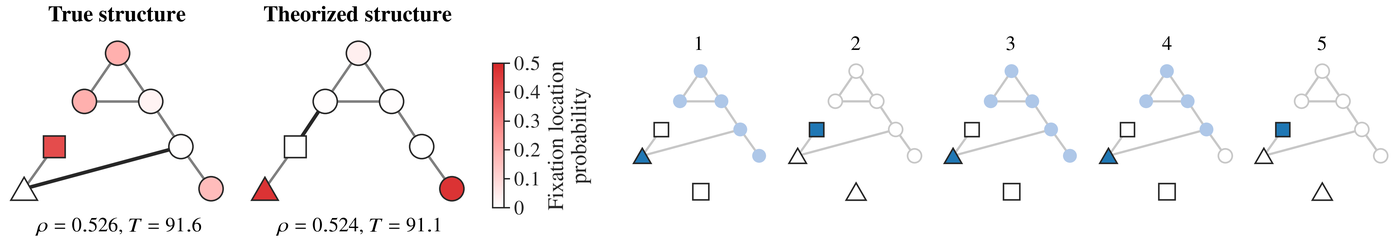

In [3]:
fig = plt.figure(figsize=(7.0, H_IN))
for k, (E, P, mv, title) in enumerate(((G, d['PG'], removed, 'True structure'), (H, d['PH'], added, 'Theorized structure'))):
  ax = fig.add_axes([0.0 + 0.172 * k, y_e - h_e, 0.168, h_e])
  fills = S.shade(S.CM_LAST, dict(enumerate(np.array(P))), 0, 0.5)
  S.draw_graph(ax, POS, [e for e in E if e not in mv], fills, R=R, shapes=MONITORED, link_lw=0.9)
  moved_links(ax, mv)
  ax.set_xlim(*XL)
  ax.set_ylim(-2.05, 1.45)
  ax.text(0, 1.4, r'\textbf{%s}' % title, ha='center', va='bottom', fontsize=8)
  ax.text(0, -1.78, r'$\rho=%.3f$, $T=%.1f$' % (d['rho'][k], d['T'][k]), ha='center', va='top', fontsize=7)
cax = fig.add_axes([0.352, y_e - h_e + 0.035, 0.008, h_e - 0.08])
ticks = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
cb = S.colorbar(fig, cax, S.CM_LAST, 0, 0.5, ticks, 'Fixation location\nprobability')
cb.set_ticklabels([r'$%g$' % x for x in ticks])
for j, ev in enumerate(d['events']):
  mut = set(ev['mutants'])
  ax = fig.add_axes([0.448 + 0.111 * j, y_e - h_e, 0.105, h_e])
  ax.set_aspect('equal')
  ax.set_axis_off()
  for u, v in G:
    a, b = np.array(POS[u], float), np.array(POS[v], float)
    unit = (b - a) / np.linalg.norm(b - a)
    phi = np.arctan2(unit[1], unit[0])
    ra = S._reach(MONITORED.get(u), R * 1.05, phi) if u in MONITORED else R * 0.92
    rb = S._reach(MONITORED.get(v), R * 1.05, phi + np.pi) if v in MONITORED else R * 0.92
    ax.plot(*zip(a + unit * ra * 0.9, b - unit * rb * 0.9), color=S.LGRAY, lw=0.8, zorder=1)
  for v, (x, y) in POS.items():
    wild = v not in mut
    if v in MONITORED:
      S.polygon(ax, (x, y), MONITORED[v], R * 1.05, S.WILD if wild else S.MUTANT, zorder=3)
    else:
      ax.add_patch(
        Circle((x, y), R * 0.92, facecolor=S.WILD if wild else S.LBLUE, edgecolor=S.LGRAY if wild else 'none', lw=0.6, zorder=2)
      )
  S.polygon(ax, (0.0, -2.25), MONITORED[ev['record']], 0.24, S.WILD, zorder=4)
  ax.set_xlim(*XL)
  ax.set_ylim(-2.6, 1.45)
  ax.text(0, 1.4, r'$%d$' % (j + 1), ha='center', va='bottom', fontsize=7)
S.save_panel(fig, 'e')